# EDA: A/B-тест кнопки «Купить» → «Купить сейчас»

Разведочный анализ до статистических выводов: какие данные пришли, как устроены группы,
где воронка теряет пользователей и как выглядит выручка.

Ноутбук только исследует данные. Все цифры для отчёта пересчитываются скриптом `run_analysis.py`,
поэтому выводы в `docs/analysis_report.md` не зависят от того, открыт ли ноутбук.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from abtest.config import DATA_PATH, FIGURES_DIR
from abtest.data_quality import clean
from abtest.metrics import daily_conversion, funnel, group_metrics

pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Данные и очистка

Сырые данные проходят те же проверки качества, что и в пайплайне: проблемные строки удаляются.

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["session_date"])
df, report, dropped = clean(raw)
print(f"строк до очистки: {len(raw):,}")
print(f"строк после очистки: {len(df):,}")
print(f"удалено: {len(dropped):,}")
df.head()

строк до очистки: 30,000
строк после очистки: 30,000
удалено: 0


,user_id,experiment_group,device,country,traffic_source,visitor_type,session_date,viewed_product,added_to_cart,purchased,revenue,session_duration
0,U000001,treatment,mobile,RU,email,new,2026-09-05,True,False,False,0.000,408
1,U000002,control,mobile,RU,social,returning,2026-09-03,True,False,False,0.000,252
2,U000003,treatment,tablet,RU,email,returning,2026-09-13,True,False,False,0.000,492
3,U000004,treatment,mobile,RU,referral,new,2026-09-06,True,False,False,0.000,571
4,U000005,control,mobile,UA,paid_search,new,2026-09-14,True,False,False,0.000,213


In [3]:
report[["check", "issues_found", "detail"]]

,check,issues_found,detail
0,user_in_both_groups,0,users in both groups: 0
1,duplicate_user_id,0,duplicated user_id: 0
2,missing_required_fields,0,rows with missing required fields: 0
3,invalid_experiment_group,0,rows with invalid experiment_group: 0
4,unknown_categories,0,rows with unknown device/source/visitor_type/c...
5,negative_revenue,0,rows with negative revenue: 0
6,funnel_order,0,rows violating funnel order: 0
7,revenue_vs_purchased,0,rows where revenue and purchased disagree: 0
8,session_date_window,0,rows outside the experiment window or with inv...


In [4]:
df.dtypes

user_id                        str
experiment_group               str
device                         str
country                        str
traffic_source                 str
visitor_type                   str
session_date        datetime64[us]
viewed_product                bool
added_to_cart                 bool
purchased                     bool
revenue                    float64
session_duration             int64
dtype: object

## 2. Размер групп

Если группы разошлись сильнее, чем позволяет случайность, дальше считать эффект бессмысленно.

In [5]:
sizes = df["experiment_group"].value_counts()
share = (sizes / sizes.sum()).round(4)
pd.DataFrame({"users": sizes, "share": share})

,users,share
experiment_group,,
treatment,15079,0.503
control,14921,0.497


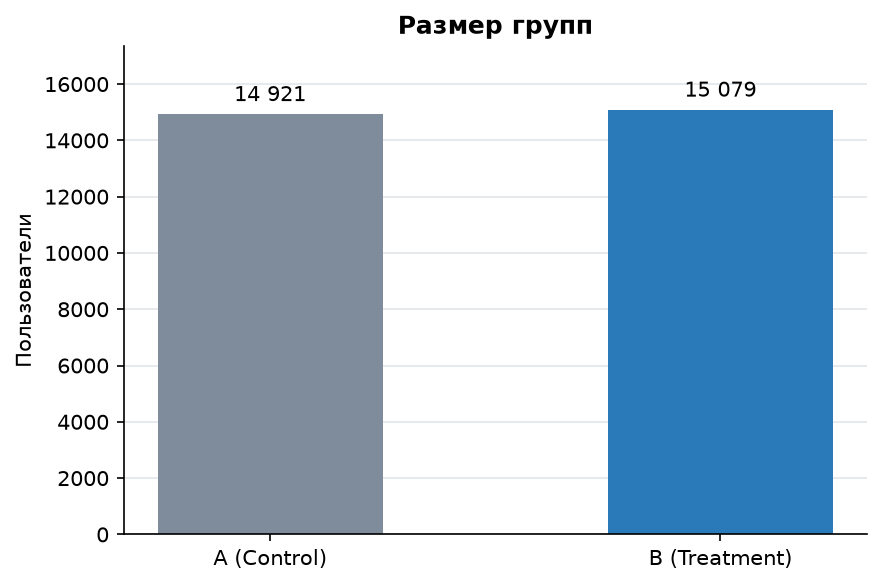

In [6]:
from IPython.display import Image

Image(FIGURES_DIR / "01_group_sizes.png")

## 3. Метрики по группам

In [7]:
metrics = group_metrics(df)
metrics

,experiment_group,users,viewers,add_to_cart_users,purchasers,revenue,avg_session_duration,conversion_rate,view_rate,add_to_cart_rate,purchase_rate,revenue_per_user,revenue_per_purchaser
0,control,14921,14304,3174,1275,"3,459,430.110",298.499,0.085,0.959,0.213,0.402,231.850,"2,713.279"
1,treatment,15079,14451,3126,1409,"3,805,478.920",296.513,0.093,0.958,0.207,0.451,252.369,"2,700.837"


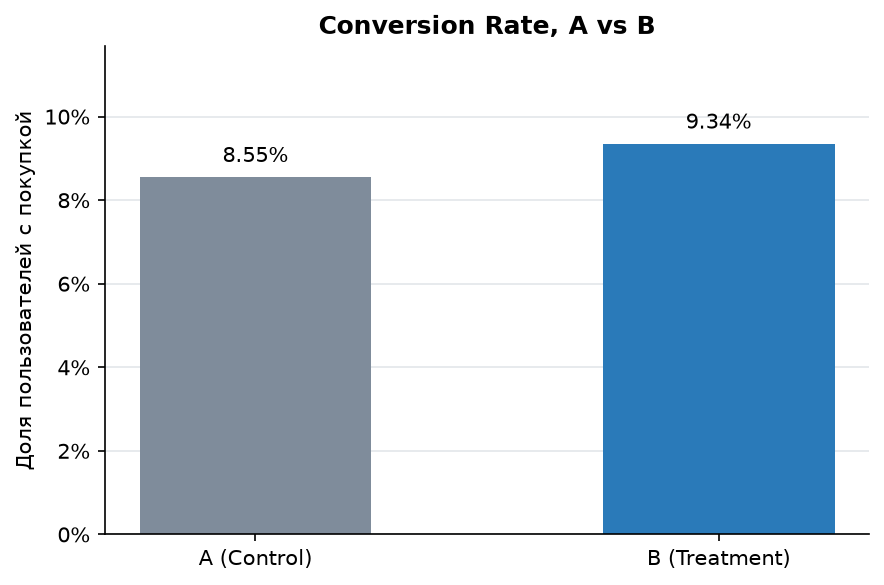

In [8]:
Image(FIGURES_DIR / "02_conversion.png")

## 4. Воронка

Где отваливаются пользователи: до просмотра товара, до корзины или уже после корзины.

In [9]:
fn = funnel(df)
fn

,control,treatment,control_pct,treatment_pct
users,14921,15079,1.000,1.000
viewed,14304,14451,0.959,0.958
added_to_cart,3174,3126,0.213,0.207
purchased,1275,1409,0.085,0.093


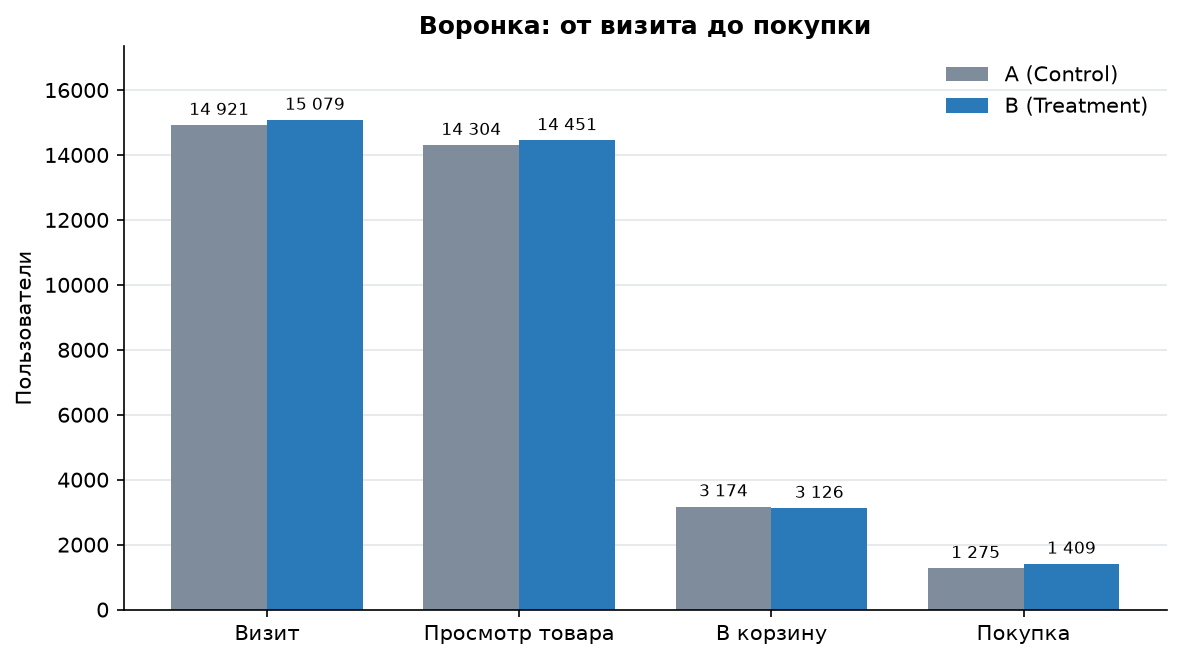

In [10]:
Image(FIGURES_DIR / "03_funnel.png")

## 5. Сегменты

Смотрим, где конверсия отличается заметно, — это кандидаты на сегментный анализ после теста.

In [11]:
for column in ["device", "traffic_source", "visitor_type"]:
    breakdown = (
        df.groupby([column, "experiment_group"], observed=True)["purchased"]
        .agg(users="size", purchasers="sum")
        .assign(conversion_rate=lambda d: d["purchasers"] / d["users"])
        .reset_index()
    )
    display(breakdown.pivot(index=column, columns="experiment_group", values="conversion_rate"))

experiment_group,control,treatment
device,,
desktop,0.082,0.090
mobile,0.087,0.096
tablet,0.075,0.078


experiment_group,control,treatment
traffic_source,,
email,0.100,0.124
organic,0.092,0.096
paid_search,0.092,0.096
referral,0.074,0.083
social,0.060,0.069


experiment_group,control,treatment
visitor_type,,
new,0.062,0.066
returning,0.124,0.139


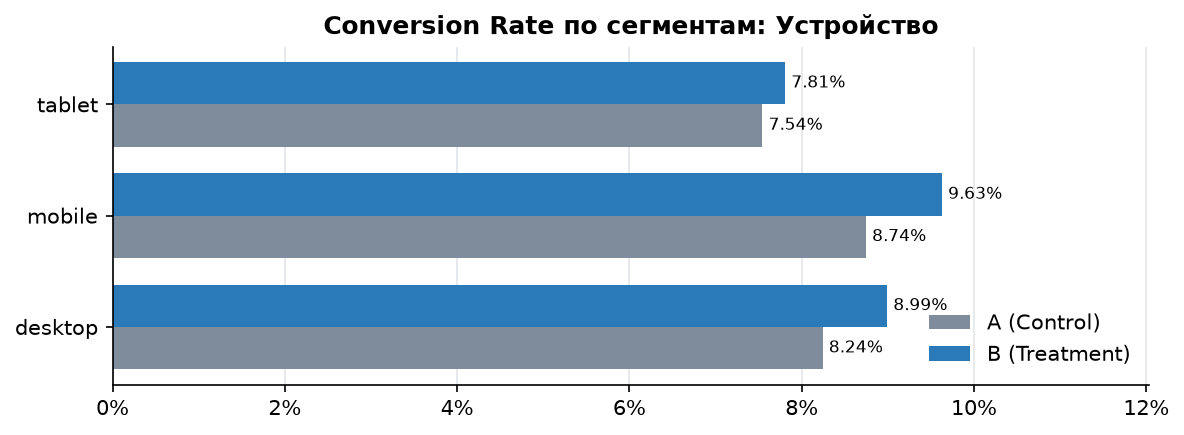

In [12]:
Image(FIGURES_DIR / "05_segments_device.png")

## 6. Динамика по дням

Резкий скачок в первые дни — сигнал эффекта новизны, после него эффект обычно остывает.

In [13]:
daily = daily_conversion(df)
daily.pivot(index="session_date", columns="experiment_group", values="conversion_rate")

experiment_group,control,treatment
session_date,,
2026-09-01,0.077,0.097
2026-09-02,0.078,0.105
2026-09-03,0.107,0.092
2026-09-04,0.087,0.102
2026-09-05,0.092,0.095
2026-09-06,0.087,0.075
2026-09-07,0.076,0.084
2026-09-08,0.092,0.100
2026-09-09,0.075,0.088


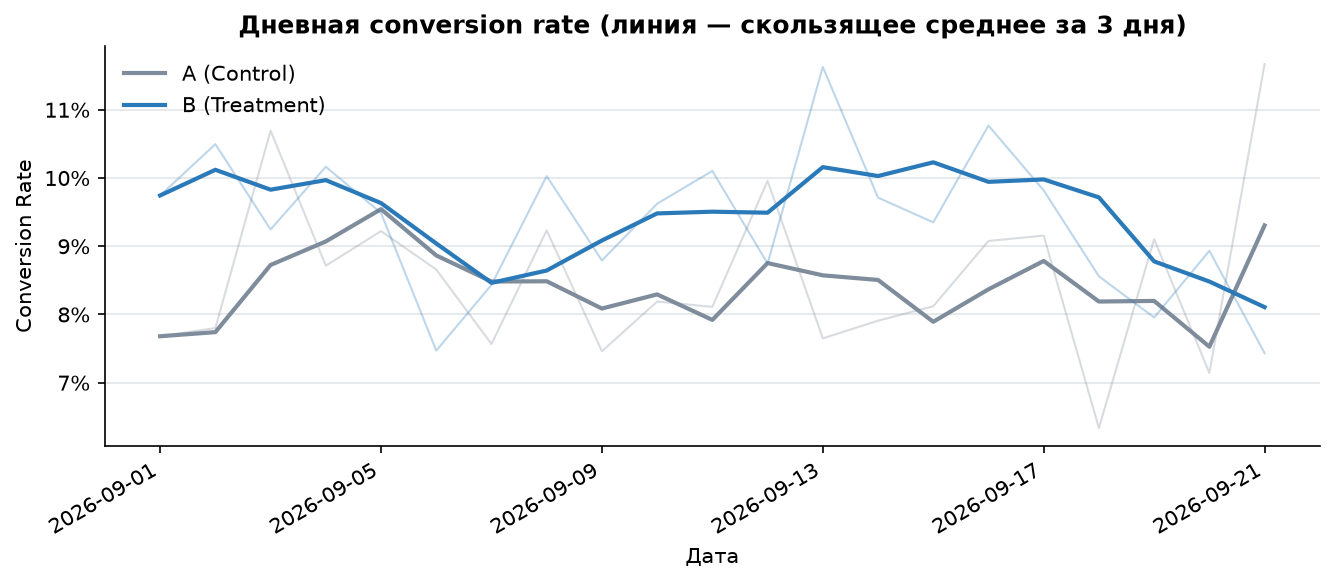

In [14]:
Image(FIGURES_DIR / "06_dynamics.png")

## 7. Выручка

Средний чек и его разброс: если Treatment меняет только конверсию, но не чек, эффект переводится в деньги
умножением на средний чек.

In [15]:
df.groupby(["experiment_group", "purchased"], observed=True)["revenue"].describe()

count      mean       std     min       25%       50%       75%        max
experiment_group purchased                                                                                
control          False     13,646.000     0.000     0.000   0.000     0.000     0.000     0.000      0.000
                 True       1,275.000 2,713.279 1,640.840 420.960 1,592.410 2,305.090 3,380.955 16,673.930
treatment        False     13,670.000     0.000     0.000   0.000     0.000     0.000     0.000      0.000
                 True       1,409.000 2,700.837 1,609.102 470.860 1,583.140 2,286.230 3,371.070 13,007.980

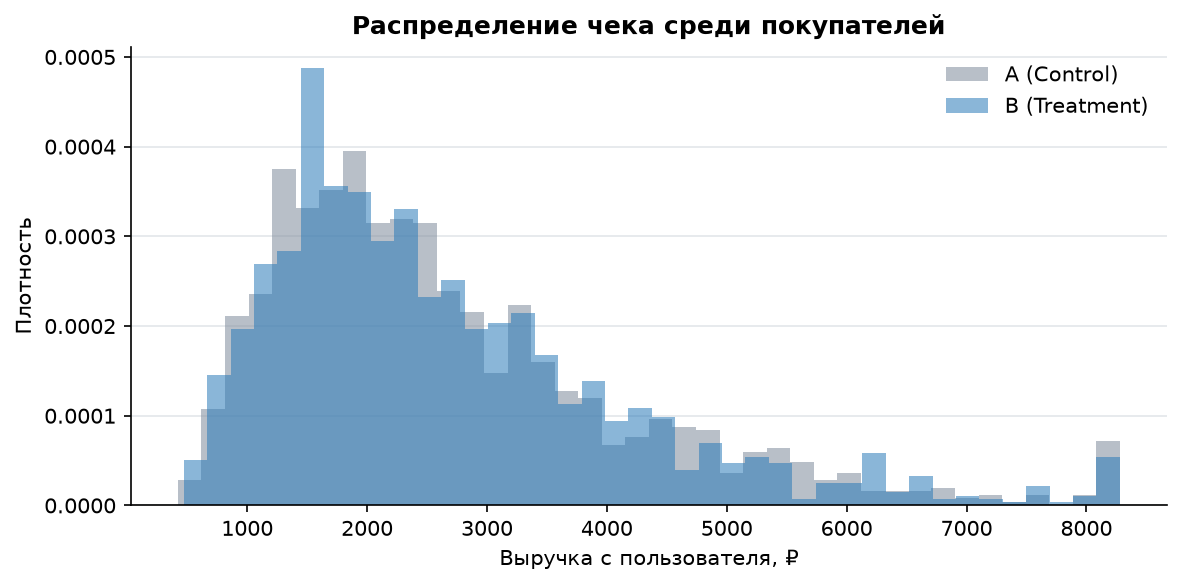

In [16]:
Image(FIGURES_DIR / "08_revenue_distribution.png")

## Выводы для перехода к статистике

1. Группы сопоставимы по размеру и составу — SRM и перекос рандомизации не видны.
2. Основное отличие между группами возникает во воронке после корзины, а не на этапе просмотра.
3. Сегменты mobile и returning показывают более заметный разрыв, но размеры подгрупп малы —
   прежде чем делать выводы, нужен формальный тест по каждому сегменту.
4. Разница конверсии выглядит небольшой относительно уровня шума, поэтому решение принимается по
   p-value и доверительному интервалу из `run_analysis.py`.